In [1]:
# import libraries

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt 
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder , StandardScaler
from sklearn.ensemble import IsolationForest
from sklearn.metrics import classification_report, confusion_matrix

import pickle 
import warnings
warnings.filterwarnings('ignore')




In [2]:
# problem statement - transaction anomaly detection using machine learning
"""
the objective of this project is to identify unusual or abnormal transaction from 
transaction data using isolation forest algorithm. The dataset contains various features related to transactions,
 and the goal is to classify transactions as either normal or abnormal based on these features.
The isolation forest algorithm is an unsupervised learning algorithm that is particularly effective for anomaly detection."""


"""
in real word transaction datasets most transaction follow normal patterns
while some transaction may have unusual values or behavior"""


"""
our goal is to analyze transaction data and built a machine learning model that can 
identify such unusual transaction automatically """

"""
KEY objective 
1. understand tha transaction dataset
2. perform exploratory data analysis(eda)
3. clean data preprocess the data
4. select relavant data 
5. apply an anomaly detection machine learning algorithm 
6. evaluate the mode 
7. test the model on a  single new transaction 
8. save the trained model for future use"""

'\nKEY objective \n1. understand tha transaction dataset\n2. perform exploratory data analysis(eda)\n3. clean data preprocess the data\n4. select relavant data \n5. apply an anomaly detection machine learning algorithm \n6. evaluate the mode \n7. test the model on a  single new transaction \n8. save the trained model for future use'

In [3]:
# data gathering

df = pd.read_csv("data/transactions.csv")
df

,Transaction_ID,Transaction_Date,Customer_Age,Transaction_Amount,Transaction_Count_24H,Account_Age_Days,Device_Type,Payment_Method,Location,Is_International
0,TXN00522,2026-03-04,49.0,1831.56,5,2368,Desktop,UPI,Hyderabad,No
1,TXN00738,2026-04-09,58.0,1435.19,1,1806,Tablet,UPI,Indore,No
2,TXN00741,2026-01-17,20.0,1373.89,5,1003,Mobile,Wallet,Pune,No
3,TXN00661,2026-03-25,45.0,3072.71,8,2061,Mobile,UPI,Hyderabad,No
4,TXN00412,2026-04-20,43.0,977.38,3,589,Mobile,UPI,Pune,No
...,...,...,...,...,...,...,...,...,...,...
998,TXN00436,2026-03-05,49.0,764.11,4,1219,Mobile,UPI,Bengaluru,No
999,TXN00103,2026-02-17,36.0,538.04,4,2478,Mobile,UPI,Pune,No
1000,TXN00347,2026-01-02,30.0,1081.64,4,1062,Mobile,Card,Hyderabad,No
1001,TXN00893,2026-04-28,43.0,2358.68,4,356,Mobile,NetBanking,Indore,No


In [4]:
df['Is_International'].value_counts()

No     909
Yes     94
Name: Is_International, dtype: int64

In [5]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1003 entries, 0 to 1002
Data columns (total 10 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Transaction_ID         1003 non-null   object 
 1   Transaction_Date       1003 non-null   object 
 2   Customer_Age           998 non-null    float64
 3   Transaction_Amount     1000 non-null   float64
 4   Transaction_Count_24H  1003 non-null   int64  
 5   Account_Age_Days       1003 non-null   int64  
 6   Device_Type            999 non-null    object 
 7   Payment_Method         1001 non-null   object 
 8   Location               1003 non-null   object 
 9   Is_International       1003 non-null   object 
dtypes: float64(2), int64(2), object(6)
memory usage: 78.5+ KB


In [6]:
# eda + preprocessing 

#1. missing value
df.isnull().sum()
df.isnull().sum()/len(df)*100


Transaction_ID           0.000000
Transaction_Date         0.000000
Customer_Age             0.498504
Transaction_Amount       0.299103
Transaction_Count_24H    0.000000
Account_Age_Days         0.000000
Device_Type              0.398804
Payment_Method           0.199402
Location                 0.000000
Is_International         0.000000
dtype: float64

In [7]:
num_columns = df[['Customer_Age' , 'Transaction_Amount']]

for i in num_columns:
    df[i] = df[i].fillna(df[i].median())

In [8]:
cat_columns = df[['Device_Type' , 'Payment_Method']]

for i in cat_columns:
    
    df[i] = df[i].fillna(df[i].mode()[0])

In [9]:
#2. handle duplicates 
df.duplicated().sum()


3

In [10]:
df = df.drop_duplicates().reset_index(drop=True)

In [11]:
# data feature analysis
# change to data and time format 

df['Transaction_Date'] = pd.to_datetime(df['Transaction_Date'])


In [12]:
df['Transaction_year'] = df['Transaction_Date'].dt.year
df['Transaction_month'] = df['Transaction_Date'].dt.month
df['Transaction_day'] = df['Transaction_Date'].dt.day
df['Transaction_dayOfWeek'] = df['Transaction_Date'].dt.dayofweek

In [13]:
df['Is_weekend'] = df['Transaction_dayOfWeek'].isin([5,6]).astype(int)

In [14]:
df.drop('Transaction_Date' , axis=1 , inplace=True)

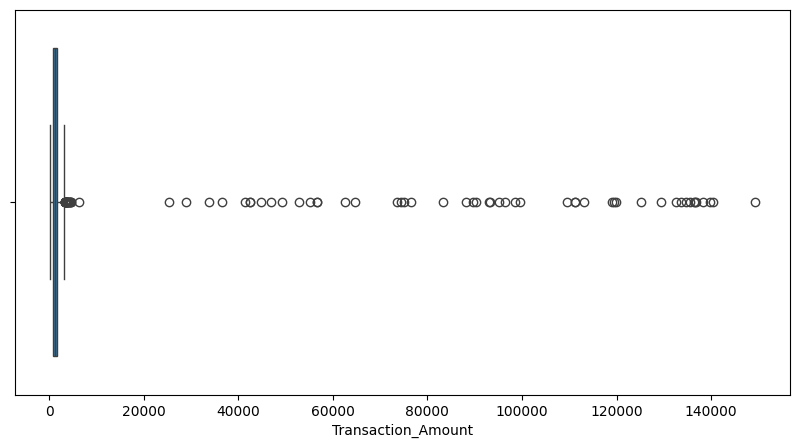

In [15]:
# outlier analysis 
plt.figure(figsize=(10 , 5))
sns.boxplot(data= df , x='Transaction_Amount')
plt.show()

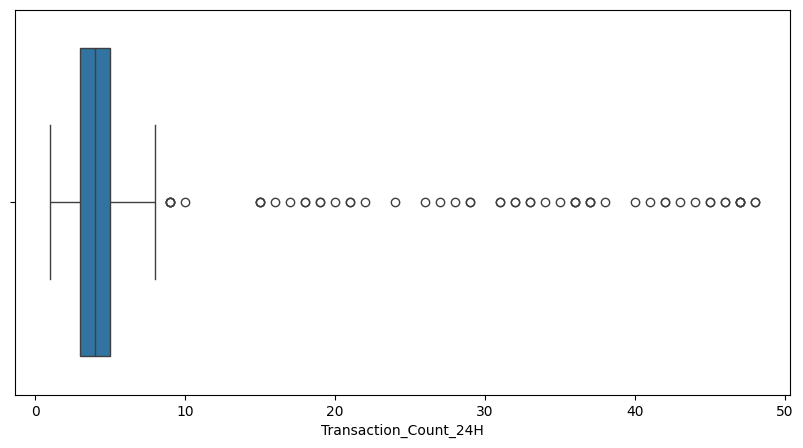

In [16]:
plt.figure(figsize=(10 , 5))
sns.boxplot(data= df , x='Transaction_Count_24H')
plt.show()

In [17]:
# summary 
"""
normally outlier remove kiye jate h lekin anomaly detection m 
unusual observation hi detect karna h , isliye genuine exterm 
value ko remove nhi karenge"""

'\nnormally outlier remove kiye jate h lekin anomaly detection m \nunusual observation hi detect karna h , isliye genuine exterm \nvalue ko remove nhi karenge'

In [18]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 14 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Transaction_ID         1000 non-null   object 
 1   Customer_Age           1000 non-null   float64
 2   Transaction_Amount     1000 non-null   float64
 3   Transaction_Count_24H  1000 non-null   int64  
 4   Account_Age_Days       1000 non-null   int64  
 5   Device_Type            1000 non-null   object 
 6   Payment_Method         1000 non-null   object 
 7   Location               1000 non-null   object 
 8   Is_International       1000 non-null   object 
 9   Transaction_year       1000 non-null   int64  
 10  Transaction_month      1000 non-null   int64  
 11  Transaction_day        1000 non-null   int64  
 12  Transaction_dayOfWeek  1000 non-null   int64  
 13  Is_weekend             1000 non-null   int32  
dtypes: float64(2), int32(1), int64(6), object(5)
memory usage

In [19]:
# categorical encoding 
df = pd.get_dummies(
    df,
    columns=['Device_Type', 'Payment_Method', 'Location', 'Is_International'],
    drop_first=True,
    dtype=int
)


In [20]:
df.drop('Transaction_ID' , axis=1 , inplace=True)

In [21]:
# train test split
x = df 

In [22]:
x_train , x_test = train_test_split(x , test_size=0.20 , random_state= 42)

In [23]:
# model training
model = IsolationForest(
    n_estimators=200 , random_state= 42

)

In [24]:
model.fit(x_train)

IsolationForest(n_estimators=200, random_state=42)

In [25]:
# model evaluation 
train_prediction = model.predict(x_train)
test_prediction = model.predict(x_test)

In [26]:
### isolation output 
"""
1 --> normal data 
-1 --> abnormal data"""

'\n1 --> normal data \n-1 --> abnormal data'

In [27]:
x_test_result = x_test.copy()
x_test_result['Anomaly'] = test_prediction

In [28]:
x_test_result.head()

,Customer_Age,Transaction_Amount,Transaction_Count_24H,Account_Age_Days,Transaction_year,Transaction_month,Transaction_day,Transaction_dayOfWeek,Is_weekend,Device_Type_Mobile,...,Payment_Method_NetBanking,Payment_Method_UPI,Payment_Method_Wallet,Location_Delhi,Location_Hyderabad,Location_Indore,Location_Mumbai,Location_Pune,Is_International_Yes,Anomaly
521,35.0,1431.68,4,1064,2026,2,2,0,0,1,...,0,0,0,0,0,0,0,0,0,1
737,44.0,1128.42,3,1785,2026,1,1,3,0,1,...,0,0,0,0,0,1,0,0,0,1
740,54.0,1217.15,4,1830,2026,1,14,2,0,0,...,0,1,0,0,0,0,0,0,0,1
660,53.0,4112.88,2,1613,2026,2,17,1,0,0,...,0,0,1,1,0,0,0,0,0,-1
411,20.0,1080.82,5,1027,2026,4,10,4,0,1,...,0,0,0,0,0,0,0,1,0,1


In [29]:
normal_count = sum(test_prediction==1)
abnormal_count = sum(test_prediction==-1)

In [30]:
print("normal", normal_count)
print("abnormal_count" , abnormal_count)

normal 126
abnormal_count 74


In [31]:
normal_per = (normal_count/len(test_prediction)) *100
abnormal_per =(abnormal_count/len(test_prediction)) *100 

In [32]:
print("normal", normal_per)
print("abnormal_count" , abnormal_per)

normal 63.0
abnormal_count 37.0


In [33]:
# isolation forest score 
score = model.decision_function(x_test)

In [34]:
x_test_result['Anomaly_score'] = score

In [35]:
x_test_result.sort_values(by = 'Anomaly_score')

,Customer_Age,Transaction_Amount,Transaction_Count_24H,Account_Age_Days,Transaction_year,Transaction_month,Transaction_day,Transaction_dayOfWeek,Is_weekend,Device_Type_Mobile,...,Payment_Method_UPI,Payment_Method_Wallet,Location_Delhi,Location_Hyderabad,Location_Indore,Location_Mumbai,Location_Pune,Is_International_Yes,Anomaly,Anomaly_score
662,26.0,74406.76,38,3,2026,1,17,5,1,0,...,0,1,1,0,0,0,0,1,-1,-0.179649
86,22.0,136503.76,42,8,2026,1,1,3,0,0,...,0,1,0,1,0,0,0,1,-1,-0.171797
941,46.0,134644.83,48,8,2026,3,24,1,0,0,...,0,0,0,0,0,1,0,1,-1,-0.146803
917,34.0,93315.31,32,13,2026,1,5,0,0,0,...,0,0,0,0,0,1,0,1,-1,-0.136495
107,46.0,113035.53,29,6,2026,1,11,6,1,0,...,0,0,1,0,0,0,0,0,-1,-0.135713
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
493,49.0,898.44,3,828,2026,1,14,2,0,1,...,0,0,0,0,0,0,0,0,1,0.091528
198,53.0,2081.01,3,367,2026,3,19,3,0,1,...,0,0,0,0,0,0,0,0,1,0.093691
617,39.0,893.32,4,1915,2026,4,8,2,0,1,...,1,0,0,0,0,0,0,0,1,0.096937
948,49.0,761.59,5,1339,2026,2,20,4,0,1,...,0,0,0,0,0,0,0,0,1,0.099339


In [36]:
# test on single data 
df.columns

Index(['Customer_Age', 'Transaction_Amount', 'Transaction_Count_24H',
       'Account_Age_Days', 'Transaction_year', 'Transaction_month',
       'Transaction_day', 'Transaction_dayOfWeek', 'Is_weekend',
       'Device_Type_Mobile', 'Device_Type_Tablet', 'Payment_Method_NetBanking',
       'Payment_Method_UPI', 'Payment_Method_Wallet', 'Location_Delhi',
       'Location_Hyderabad', 'Location_Indore', 'Location_Mumbai',
       'Location_Pune', 'Is_International_Yes'],
      dtype='object')

In [37]:
new_transaction = pd.DataFrame({
    'Customer_Age': [25],
    'Transaction_Amount': [1500000],
    'Transaction_Count_24H': [3],
    'Account_Age_Days': [450],
    'Transaction_year': [2026],
    'Transaction_month': [9],
    'Transaction_day': [20],
    'Transaction_dayOfWeek': [6],
    'Is_weekend': [1],
    'Device_Type_Mobile': [1],
    'Device_Type_Tablet': [0],
    'Payment_Method_NetBanking': [0],
    'Payment_Method_UPI': [1],
    'Payment_Method_Wallet': [0],
    'Location_Delhi': [0],
    'Location_Hyderabad': [0],
    'Location_Indore': [1],
    'Location_Mumbai': [0],
    'Location_Pune': [0],
    'Is_International_Yes': [0]
})

In [38]:
new_transaction = new_transaction.reindex(columns=x_train.columns , fill_value= 0)

In [39]:
predicted = model.predict(new_transaction)

In [40]:
if predicted[0] ==-1:
    print("abnorMAL")

else : 
    print("normal")

abnorMAL


In [41]:
# save model
import pickle
import joblib

joblib.dump(model , "abnormal_model.pkl")

['abnormal_model.pkl']